# Analisis Buka Kafe dengan GeoPandas

**Mata Kuliah:** Computer Graphics (AFL 2), Universitas Ciputra Surabaya
**Tim:** Filemon Jose Hagen, Hafizd Dharma Saputra Hardiono

Notebook ini mengikuti alur Week 5 dan Week 6:

1. **Week 5:** geometri Point, LineString, Polygon; atribut geometri (`geom_type`, `area`, `length`, `bounds`, `is_valid`); predikat spasial (`within`, `contains`, `touches`, `intersects`, `distance`).
2. **Week 6:** `points_from_xy` dengan CRS → cek input dengan `assert` → `to_crs("EPSG:32749")` → `buffer` → `sjoin(predicate="intersects")` → `groupby().nunique()` → checkpoint → fungsi plot → ekspor CSV.

Ditambah materi grafika 2D: transformasi matriks homogen, *clipping*, *compositing*, dan animasi. Hasil angkanya dicek sama dengan pipeline utama (`scripts/gis_pipeline.py`) yang dipakai web peta.

In [1]:
%pip install -q -r ../requirements.txt

Note: you may need to restart the kernel to use updated packages.


## 0. Persiapan

In [2]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from shapely.geometry import Point, Polygon, LineString
from shapely import affinity
from IPython.display import Image, display

# Notebook bisa dibuka dari root repo maupun dari folder notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
sys.path.insert(0, str(ROOT))

input_crs = "EPSG:4326"       # derajat (lon, lat), format penyimpanan GeoJSON
analysis_crs = "EPSG:32749"   # UTM zona 49 Selatan, meter, untuk jarak & buffer
baseline_m, skenario_m = 500, 1000

np.set_printoptions(suppress=True, precision=2, linewidth=120)
print("Geopandas:", gpd.__version__)
print("pandas:", pd.__version__)
print("Root repo:", ROOT.name)

Geopandas: 1.2.0
pandas: 3.1.0
Root repo: comgraph-afl-2


## 1. Membuat GeoDataFrame dari data mentah

| Lapisan | Geometri | Sumber |
| --- | --- | --- |
| Titik kampus | Point | `data/raw/universities.geojson` (koordinat OSM yang diverifikasi tim) |
| Perimeter kampus | Polygon | `data/raw/osm/genuine_campus_polygons.json` (way OSM) |
| Kafe eksisting | Point | `data/raw/osm/overpass_cafes_raw.json` (OpenStreetMap Overpass API) |
| Kandidat lahan | Point | `data/raw/survey_land_candidates.geojson` (observasi Google Street View) |

Seperti Week 6, CRS langsung ditetapkan saat GeoDataFrame dibuat.

In [3]:
# Kafe OSM: tabel lon/lat -> points_from_xy
overpass = json.loads((RAW / "osm" / "overpass_cafes_raw.json").read_text(encoding="utf-8"))
cafe_data = {"osm_id": [], "nama": [], "lon": [], "lat": []}
for el in overpass["elements"]:
    pos = el if el["type"] == "node" else el["center"]
    cafe_data["osm_id"].append(f"{el['type']}/{el['id']}")
    cafe_data["nama"].append(el.get("tags", {}).get("name", "(tanpa nama)"))
    cafe_data["lon"].append(pos["lon"])
    cafe_data["lat"].append(pos["lat"])

kafe = gpd.GeoDataFrame(
    cafe_data,
    geometry=gpd.points_from_xy(cafe_data["lon"], cafe_data["lat"]),
    crs=input_crs,
)

# Perimeter kampus: daftar koordinat -> Polygon
raw_poly = json.loads((RAW / "osm" / "genuine_campus_polygons.json").read_text(encoding="utf-8"))
kampus_poly = gpd.GeoDataFrame(
    {
        "id": list(raw_poly),
        "nama": [v["name"] for v in raw_poly.values()],
        "luas_osm_ha": [v["area_ha"] for v in raw_poly.values()],
    },
    geometry=[Polygon(v["coordinates"]) for v in raw_poly.values()],
    crs=input_crs,
)

# Titik kampus dan kandidat lahan: langsung dari GeoJSON (CRS ikut dari file)
kampus = gpd.read_file(RAW / "universities.geojson")[["id", "institution", "campus_name", "geometry"]]
lahan = gpd.read_file(RAW / "survey_land_candidates.geojson")[
    ["id", "name", "status", "road_type", "imagery_date", "evidence_url", "geometry"]
]

print("Kandidat lahan (5 baris pertama):")
print(lahan[["id", "status", "road_type"]].head().to_string(index=False))

Kandidat lahan (5 baris pertama):
           id                                          status road_type
SV-UNAIR-A-01              Rumah atau bangunan tempat tinggal      gang
SV-UNAIR-A-02 Bangunan yang telah digunakan untuk fungsi lain       NaN
SV-UNAIR-A-03 Bangunan yang telah digunakan untuk fungsi lain       NaN
SV-UNAIR-C-01              Rumah atau bangunan tempat tinggal      gang
SV-UNAIR-C-02             Lahan yang tersedia untuk disewakan      gang


### 1.1 Cek input (Week 6)

In [4]:
expected = {
    # nama: (layer, kolom id, jumlah baris, tipe geometri)
    "kafe": (kafe, "osm_id", 206, "Point"),
    "kampus": (kampus, "id", 8, "Point"),
    "kampus_poly": (kampus_poly, "id", 8, "Polygon"),
    "lahan": (lahan, "id", 22, "Point"),
}
for name, (layer, id_column, expected_rows, geom_type) in expected.items():
    print(f"{name}: {len(layer)} rows; CRS = {layer.crs}")
    print("  geometry types:", layer.geometry.geom_type.unique().tolist())
    print("  bounds:", layer.total_bounds.round(3).tolist())
    assert len(layer) == expected_rows
    assert layer.crs.to_epsg() == 4326
    assert layer.geometry.notna().all() and layer.is_valid.all()
    assert layer[id_column].is_unique
    assert layer.geometry.geom_type.eq(geom_type).all()

print("Input checks passed.")

kafe: 206 rows; CRS = EPSG:4326
  geometry types: ['Point']
  bounds: [112.721, -7.329, 112.806, -7.241]
kampus: 8 rows; CRS = EPSG:4326
  geometry types: ['Point']
  bounds: [112.745, -7.32, 112.812, -7.26]
kampus_poly: 8 rows; CRS = EPSG:4326
  geometry types: ['Polygon']
  bounds: [112.744, -7.323, 112.813, -7.259]
lahan: 22 rows; CRS = EPSG:4326
  geometry types: ['Point']
  bounds: [112.743, -7.319, 112.81, -7.259]
Input checks passed.


In [5]:
# Tabel metadata lapisan (syarat: >= 2 layer + sumber + CRS)
layer_meta = pd.DataFrame([
    ["Titik kampus", "Point", len(kampus), "OSM, diverifikasi tim"],
    ["Perimeter kampus", "Polygon", len(kampus_poly), "OpenStreetMap way"],
    ["Kafe eksisting", "Point", len(kafe), "OpenStreetMap Overpass API (ODbL)"],
    ["Kandidat lahan", "Point", len(lahan), "Observasi Google Street View, 1-2 Nov 2026"],
], columns=["Lapisan", "Geometri", "Fitur", "Sumber"])
layer_meta["CRS simpan"] = input_crs
layer_meta["CRS analisis"] = analysis_crs
layer_meta

,Lapisan,Geometri,Fitur,Sumber,CRS simpan,CRS analisis
0,Titik kampus,Point,8,"OSM, diverifikasi tim",EPSG:4326,EPSG:32749
1,Perimeter kampus,Polygon,8,OpenStreetMap way,EPSG:4326,EPSG:32749
2,Kafe eksisting,Point,206,OpenStreetMap Overpass API (ODbL),EPSG:4326,EPSG:32749
3,Kandidat lahan,Point,22,"Observasi Google Street View, 1-2 Nov 2026",EPSG:4326,EPSG:32749


## 2. Proyeksi ke CRS metrik

Derajat bukan satuan jarak. Semua lapisan diubah ke EPSG:32749 supaya `buffer(500)` berarti 500 meter.

In [6]:
kafe_m = kafe.to_crs(analysis_crs)
kampus_m = kampus.to_crs(analysis_crs)
kampus_poly_m = kampus_poly.to_crs(analysis_crs)
lahan_m = lahan.to_crs(analysis_crs)

print("Original campus coordinates :", tuple(kampus.geometry.iloc[0].coords[0]))
print("Projected campus coordinates:", tuple(round(v, 1) for v in kampus_m.geometry.iloc[0].coords[0]))
print("Analysis CRS:", kampus_m.crs)
print("Linear unit:", kampus_m.crs.axis_info[0].unit_name)

for layer in (kafe_m, kampus_m, kampus_poly_m, lahan_m):
    assert layer.crs == kampus_m.crs
    assert layer.crs.to_epsg() == 32749

Original campus coordinates : (112.7585415, -7.2647041)
Projected campus coordinates: (694150.9, 9196612.0)
Analysis CRS: EPSG:32749
Linear unit: metre


## 3. Atribut geometri dan predikat spasial (Week 5)

Atribut poligon kampus dihitung dalam meter. Lalu predikat `within`, `touches`, `intersects`, dan `contains` dipakai untuk kandidat di sekitar Ubaya Tenggilis.

In [7]:
atribut_kampus = kampus_poly_m[["id", "luas_osm_ha"]].assign(
    geom_type=kampus_poly_m.geom_type,
    luas_hitung_ha=(kampus_poly_m.area / 10_000).round(2),
    keliling_m=kampus_poly_m.length.round(0),
    is_valid=kampus_poly_m.is_valid,
)
print(atribut_kampus.to_string(index=False))

             id  luas_osm_ha geom_type  luas_hitung_ha  keliling_m  is_valid
 UNAIR-KAMPUS-A         7.10   Polygon            7.10      1098.0      True
 UNAIR-KAMPUS-B        15.74   Polygon           15.74      1624.0      True
 UNAIR-KAMPUS-C        60.90   Polygon           60.90      3540.0      True
   UKWMS-DINOYO         1.42   Polygon            1.42       457.0      True
UKWMS-KALIJUDAN         2.28   Polygon            2.28       812.0      True
  UKWMS-PAKUWON         5.02   Polygon            5.02       937.0      True
   UBAYA-NGAGEL         0.83   Polygon            0.83       397.0      True
UBAYA-TENGGILIS         8.79   Polygon            8.79      1487.0      True


In [8]:
tenggilis_poly = kampus_poly_m.set_index("id").loc["UBAYA-TENGGILIS", "geometry"]
tenggilis_titik = kampus_m.set_index("id").loc["UBAYA-TENGGILIS", "geometry"]
tenggilis_buffer = tenggilis_titik.buffer(baseline_m)

dekat_tenggilis = lahan_m[lahan_m["id"].str.startswith("SV-UBAYA-TENGGILIS")]
predicate_table = pd.DataFrame([
    {
        "lahan": row.id,
        "within buffer 500 m": row.geometry.within(tenggilis_buffer),
        "buffer contains lahan": tenggilis_buffer.contains(row.geometry),
        "touches buffer": row.geometry.touches(tenggilis_buffer),
        "intersects kampus": row.geometry.intersects(tenggilis_poly),
        "jarak ke titik kampus (m)": round(row.geometry.distance(tenggilis_titik), 1),
        "jarak ke pagar kampus (m)": round(row.geometry.distance(tenggilis_poly), 1),
    }
    for row in dekat_tenggilis.itertuples()
])
print(predicate_table.to_string(index=False))

                lahan  within buffer 500 m  buffer contains lahan  touches buffer  intersects kampus  jarak ke titik kampus (m)  jarak ke pagar kampus (m)
SV-UBAYA-TENGGILIS-01                 True                   True           False              False                      238.7                       83.5
SV-UBAYA-TENGGILIS-02                 True                   True           False              False                      330.1                      104.3
SV-UBAYA-TENGGILIS-03                 True                   True           False              False                      169.6                       23.6
SV-UBAYA-TENGGILIS-04                 True                   True           False              False                      431.8                      188.5
SV-UBAYA-TENGGILIS-05                False                  False           False              False                      502.6                      255.6


## 4. Buffer: baseline 500 m dan skenario 1 km

In [9]:
buffers_500 = kampus_m[["id", "geometry"]].copy()
buffers_500["geometry"] = buffers_500.geometry.buffer(baseline_m)
buffers_1000 = kampus_m[["id", "geometry"]].copy()
buffers_1000["geometry"] = buffers_1000.geometry.buffer(skenario_m)

print(buffers_500[["id"]].assign(
    geometry_type=buffers_500.geometry.geom_type,
    area_500m_ha=(buffers_500.area / 10_000).round(1),
    area_1km_ha=(buffers_1000.area / 10_000).round(1),
).to_string(index=False))

assert len(buffers_500) == len(buffers_1000) == len(kampus_m)
assert buffers_500.geometry.geom_type.eq("Polygon").all()
assert buffers_1000.geometry.geom_type.eq("Polygon").all()

             id geometry_type  area_500m_ha  area_1km_ha
 UNAIR-KAMPUS-A       Polygon          78.4        313.7
 UNAIR-KAMPUS-B       Polygon          78.4        313.7
 UNAIR-KAMPUS-C       Polygon          78.4        313.7
   UKWMS-DINOYO       Polygon          78.4        313.7
UKWMS-KALIJUDAN       Polygon          78.4        313.7
  UKWMS-PAKUWON       Polygon          78.4        313.7
   UBAYA-NGAGEL       Polygon          78.4        313.7
UBAYA-TENGGILIS       Polygon          78.4        313.7


## 5. Spatial join

1. **Kafe OSM × buffer kampus** (`sjoin`, `how="left"`, `predicate="intersects"`): kafe mana yang ada di jangkauan kampus.
2. **Kandidat lahan → kampus terdekat** (`sjoin_nearest`): jarak dan status di dalam/luar buffer.
3. **Kafe OSM dalam 500 m dari tiap kandidat** (buffer kandidat + `sjoin`): ukuran kompetisi.

In [10]:
# 5.1 Kafe x buffer kampus. Satu kafe bisa masuk dua buffer yang bertumpuk (contoh: Unair A dan B).
def kafe_per_kampus(buffers):
    matches = gpd.sjoin(
        buffers[["id", "geometry"]],
        kafe_m[["osm_id", "geometry"]],
        how="left",
        predicate="intersects",
    )
    return matches.groupby("id")["osm_id"].nunique()

def kafe_terjangkau(buffers):
    matches = gpd.sjoin(
        kafe_m[["osm_id", "geometry"]],
        buffers[["id", "geometry"]],
        how="left",
        predicate="intersects",
    )
    return matches.groupby("osm_id")["id"].nunique() > 0

cakupan_kafe = kafe_m[["osm_id"]].copy()
cakupan_kafe["dalam_500m"] = cakupan_kafe["osm_id"].map(kafe_terjangkau(buffers_500))
cakupan_kafe["dalam_1000m"] = cakupan_kafe["osm_id"].map(kafe_terjangkau(buffers_1000))
print("Kafe unik dalam buffer 500 m:", int(cakupan_kafe["dalam_500m"].sum()), "dari", len(cakupan_kafe))
print("Kafe unik dalam buffer 1 km  :", int(cakupan_kafe["dalam_1000m"].sum()), "dari", len(cakupan_kafe))

Kafe unik dalam buffer 500 m: 23 dari 206
Kafe unik dalam buffer 1 km  : 59 dari 206


In [11]:
# 5.2 Kandidat lahan -> kampus terdekat
lahan_j = gpd.sjoin_nearest(
    lahan_m,
    kampus_m[["id", "campus_name", "geometry"]],
    how="left",
    distance_col="jarak_kampus_m",
    lsuffix="lahan",
    rsuffix="kampus",
)
assert lahan_j["id_lahan"].is_unique, "Ada kandidat yang berjarak sama ke dua kampus"

status_bisa_disewa = {"Lahan kosong", "Lahan yang tersedia untuk disewakan"}
lahan_j["dalam_500m"] = lahan_j["jarak_kampus_m"] <= baseline_m
lahan_j["dalam_1000m"] = lahan_j["jarak_kampus_m"] <= skenario_m
lahan_j["bisa_disewa"] = lahan_j["status"].isin(status_bisa_disewa)
lahan_j["layak_500m"] = lahan_j["dalam_500m"] & lahan_j["bisa_disewa"]
lahan_j["layak_1000m"] = lahan_j["dalam_1000m"] & lahan_j["bisa_disewa"]

# 5.3 Kompetisi: kafe OSM dalam 500 m dari tiap kandidat
lahan_buffer = lahan_m[["id", "geometry"]].copy()
lahan_buffer["geometry"] = lahan_buffer.geometry.buffer(500)
kompetisi = gpd.sjoin(lahan_buffer, kafe_m[["osm_id", "geometry"]], how="left", predicate="intersects")
lahan_j["kafe_osm_500m"] = (
    lahan_j["id_lahan"].map(kompetisi.groupby("id")["osm_id"].nunique()).fillna(0).astype(int)
)

print(lahan_j[["id_lahan", "id_kampus", "jarak_kampus_m", "status", "kafe_osm_500m", "layak_500m", "layak_1000m"]]
      .round(1).to_string(index=False))

             id_lahan       id_kampus  jarak_kampus_m                                          status  kafe_osm_500m  layak_500m  layak_1000m
        SV-UNAIR-A-01  UNAIR-KAMPUS-A           370.8              Rumah atau bangunan tempat tinggal              3       False        False
        SV-UNAIR-A-02  UNAIR-KAMPUS-B           426.9 Bangunan yang telah digunakan untuk fungsi lain              7       False        False
        SV-UNAIR-A-03  UNAIR-KAMPUS-A           178.2 Bangunan yang telah digunakan untuk fungsi lain              2       False        False
        SV-UNAIR-C-01  UNAIR-KAMPUS-C           541.0              Rumah atau bangunan tempat tinggal              0       False        False
        SV-UNAIR-C-02  UNAIR-KAMPUS-C           465.8             Lahan yang tersedia untuk disewakan              0        True         True
  SV-UKWMS-PAKUWON-01   UKWMS-PAKUWON           258.6                                    Lahan kosong              0        True         True
  SV-U

## 6. Ringkasan per kampus: baseline 500 m vs skenario 1 km

In [12]:
ringkas_lahan = lahan_j.groupby("id_kampus").agg(
    kandidat=("id_lahan", "nunique"),
    kandidat_500m=("dalam_500m", "sum"),
    kandidat_1000m=("dalam_1000m", "sum"),
    layak_500m=("layak_500m", "sum"),
    layak_1000m=("layak_1000m", "sum"),
)
per_kampus = kampus[["id", "campus_name"]].copy()
per_kampus["kafe_osm_500m"] = per_kampus["id"].map(kafe_per_kampus(buffers_500))
per_kampus["kafe_osm_1000m"] = per_kampus["id"].map(kafe_per_kampus(buffers_1000))
per_kampus = per_kampus.join(ringkas_lahan, on="id")
angka = per_kampus.columns.drop(["id", "campus_name"])
per_kampus[angka] = per_kampus[angka].fillna(0).astype(int)

print("Total kandidat layak:", int(per_kampus["layak_500m"].sum()), "(500 m) vs",
      int(per_kampus["layak_1000m"].sum()), "(1 km)")
per_kampus

Total kandidat layak: 4 (500 m) vs 5 (1 km)


,id,campus_name,kafe_osm_500m,kafe_osm_1000m,kandidat,kandidat_500m,kandidat_1000m,layak_500m,layak_1000m
0,UNAIR-KAMPUS-A,Kampus A Universitas Airlangga,2,20,2,2,2,0,0
1,UNAIR-KAMPUS-B,Kampus B Universitas Airlangga,8,21,3,3,3,0,0
2,UNAIR-KAMPUS-C,Kampus C Universitas Airlangga,0,0,3,2,3,1,1
3,UKWMS-DINOYO,Universitas Katolik Widya Mandala Surabaya Kam...,4,17,2,2,2,0,0
4,UKWMS-KALIJUDAN,Universitas Katolik Widya Mandala Surabaya Kam...,1,2,1,1,1,0,0
5,UKWMS-PAKUWON,Universitas Katolik Widya Mandala Surabaya Kam...,0,1,3,3,3,2,2
6,UBAYA-NGAGEL,Universitas Surabaya Kampus Ngagel,5,7,3,3,3,0,0
7,UBAYA-TENGGILIS,Universitas Surabaya Kampus Tenggilis,3,4,5,4,5,1,2


### 6.1 Checkpoint: hasil GeoPandas = hasil pipeline

Angka di atas dibandingkan dengan file yang dipakai web (`data/processed/`). Jika ada yang beda, `assert` akan gagal.

In [13]:
pipeline_kampus = pd.read_csv(PROC / "hasil_per_kampus.csv").set_index("kampus_id")
pipeline_kafe = gpd.read_file(PROC / "osm_cafes.geojson")
cek = per_kampus.set_index("id")

assert (cek["kandidat"] == pipeline_kampus["kandidat_teramati"]).all()
assert (cek["kandidat_500m"] == pipeline_kampus["kandidat_dalam_500m"]).all()
assert (cek["kandidat_1000m"] == pipeline_kampus["kandidat_dalam_1000m"]).all()
assert (cek["layak_500m"] == pipeline_kampus["layak_500m"]).all()
assert (cek["layak_1000m"] == pipeline_kampus["layak_1000m"]).all()
assert int(cakupan_kafe["dalam_500m"].sum()) == int(pipeline_kafe["is_in_buffer_500m"].sum())
assert int(cakupan_kafe["dalam_1000m"].sum()) == int(pipeline_kafe["is_in_buffer_1000m"].sum())
print("Checkpoint passed: GeoPandas dan pipeline memberi hasil yang sama.")

Checkpoint passed: GeoPandas dan pipeline memberi hasil yang sama.


## 7. Skor kelayakan kandidat

Skor memakai fungsi yang sama dengan pipeline dan web (`calculate_transparent_feasibility_score`), dengan input dari GeoPandas: jarak ke kampus, jumlah kafe OSM dalam 500 m, dan tipe jalan dari Street View. Komponen yang belum ada datanya (harga sewa, luas, gerbang, indikator mahasiswa) tidak ditebak; skor dinormalisasi ke komponen yang tersedia dan cakupannya ditampilkan.

In [14]:
from scripts.gis_pipeline import calculate_transparent_feasibility_score as skor_kelayakan

def hitung_skor(row):
    hasil = skor_kelayakan(
        distance_meters=row["jarak_kampus_m"],
        nearby_cafes_count=int(row["kafe_osm_500m"]),
        road_type=row["road_type"] if isinstance(row["road_type"], str) else None,
        radius_mode="baseline_500m",
    )
    return pd.Series({"skor_500m": hasil["score_normalized"], "cakupan_data_pct": hasil["coverage"]})

lahan_j[["skor_500m", "cakupan_data_pct"]] = lahan_j.apply(hitung_skor, axis=1)
peringkat = (
    lahan_j.sort_values(["layak_500m", "layak_1000m", "skor_500m"], ascending=False)
    [["id_lahan", "name", "id_kampus", "jarak_kampus_m", "status", "road_type", "kafe_osm_500m",
      "layak_500m", "layak_1000m", "skor_500m", "cakupan_data_pct"]]
    .reset_index(drop=True)
)
peringkat.insert(0, "peringkat", range(1, len(peringkat) + 1))

pipeline_skor = pd.read_csv(PROC / "peringkat_kandidat.csv").set_index("id")["skor_500m"]
assert (peringkat.set_index("id_lahan")["skor_500m"] == pipeline_skor.reindex(peringkat["id_lahan"])).all()
print("Skor sama dengan pipeline untuk", len(peringkat), "kandidat.")
peringkat.round(1)

Skor sama dengan pipeline untuk 22 kandidat.


,peringkat,id_lahan,name,id_kampus,jarak_kampus_m,status,road_type,kafe_osm_500m,layak_500m,layak_1000m,skor_500m,cakupan_data_pct
0,1,SV-UBAYA-TENGGILIS-01,Lahan berpagar ditumbuhi semak Jl. Raya Kaliru...,UBAYA-TENGGILIS,238.7,Lahan kosong,utama,1,True,True,78.0,50.0
1,2,SV-UKWMS-PAKUWON-01,Lahan terbuka bertembok barat UKWMS Pakuwon City,UKWMS-PAKUWON,258.6,Lahan kosong,NaN,0,True,True,57.5,40.0
2,3,SV-UKWMS-PAKUWON-02,Lahan terbuka berumput barat laut UKWMS Pakuwo...,UKWMS-PAKUWON,474.4,Lahan kosong,NaN,0,True,True,42.5,40.0
3,4,SV-UNAIR-C-02,Lahan berpagar disewakan Jl. Mulyorejo Utara 221,UNAIR-KAMPUS-C,465.8,Lahan yang tersedia untuk disewakan,gang,0,True,True,40.0,50.0
4,5,SV-UBAYA-TENGGILIS-05,Lahan kosong berpagar di jalan samping Raya Ka...,UBAYA-TENGGILIS,502.6,Lahan kosong,gang,0,False,True,16.0,50.0
5,6,SV-UNAIR-A-03,Gedung aktif Jl. Prof. Dr. Moestopo,UNAIR-KAMPUS-A,178.2,Bangunan yang telah digunakan untuk fungsi lain,NaN,2,False,False,82.5,40.0
6,7,SV-UBAYA-TENGGILIS-03,Rumah berpagar Jl. Tenggilis Mejoyo,UBAYA-TENGGILIS,169.6,Rumah atau bangunan tempat tinggal,NaN,2,False,False,82.5,40.0
7,8,SV-UBAYA-NGAGEL-01,Deretan toko aktif ujung Jl. Pumpungan I,UBAYA-NGAGEL,241.5,Bangunan yang telah digunakan untuk fungsi lain,NaN,2,False,False,82.5,40.0
8,9,SV-UNAIR-B-01,Hotel aktif Jl. Bunga Lou,UNAIR-KAMPUS-B,273.4,Bangunan yang telah digunakan untuk fungsi lain,NaN,3,False,False,82.5,40.0
9,10,SV-UBAYA-NGAGEL-03,Rumah bertingkat Jl. Ngagel Madya V,UBAYA-NGAGEL,219.9,Rumah atau bangunan tempat tinggal,NaN,3,False,False,82.5,40.0


## 8. Peta: model titik, garis, dan poligon

- **Poligon:** buffer 1 km (garis putus-putus), buffer 500 m (isi transparan), perimeter kampus.
- **Garis:** dari tiap kandidat layak ke kampus terdekat (`LineString`), dengan label jaraknya.
- **Titik:** kafe OSM, kandidat lahan, titik kampus.

Buffer yang bertumpuk (Unair A dan B) terlihat lebih gelap: efek **compositing** transparansi. Kafe di luar area 1 km dibuang dengan **clipping** (`gpd.clip`).

In [15]:
# Clipping: hanya kafe di dalam gabungan buffer 1 km
area_1km = buffers_1000.dissolve()
kafe_terpotong = gpd.clip(kafe_m, area_1km)
print("Clipping:", len(kafe_m), "kafe ->", len(kafe_terpotong), "kafe di dalam area 1 km")

# Garis: kandidat layak -> titik kampus terdekat
titik_kampus = kampus_m.set_index("id").geometry
layak = lahan_j[lahan_j["layak_1000m"]]
garis = gpd.GeoDataFrame(
    {"id": layak["id_lahan"].to_list(), "jarak_m": layak["jarak_kampus_m"].to_list()},
    geometry=[LineString([g, titik_kampus[k]]) for g, k in zip(layak.geometry, layak["id_kampus"])],
    crs=analysis_crs,
)
print(garis.assign(geom_type=garis.geom_type, panjang_m=garis.length.round(1))
      [["id", "geom_type", "panjang_m"]].to_string(index=False))
assert np.allclose(garis.length, garis["jarak_m"])

Clipping: 206 kafe -> 59 kafe di dalam area 1 km
                   id  geom_type  panjang_m
        SV-UNAIR-C-02 LineString      465.8
  SV-UKWMS-PAKUWON-01 LineString      258.6
  SV-UKWMS-PAKUWON-02 LineString      474.4
SV-UBAYA-TENGGILIS-01 LineString      238.7
SV-UBAYA-TENGGILIS-05 LineString      502.6


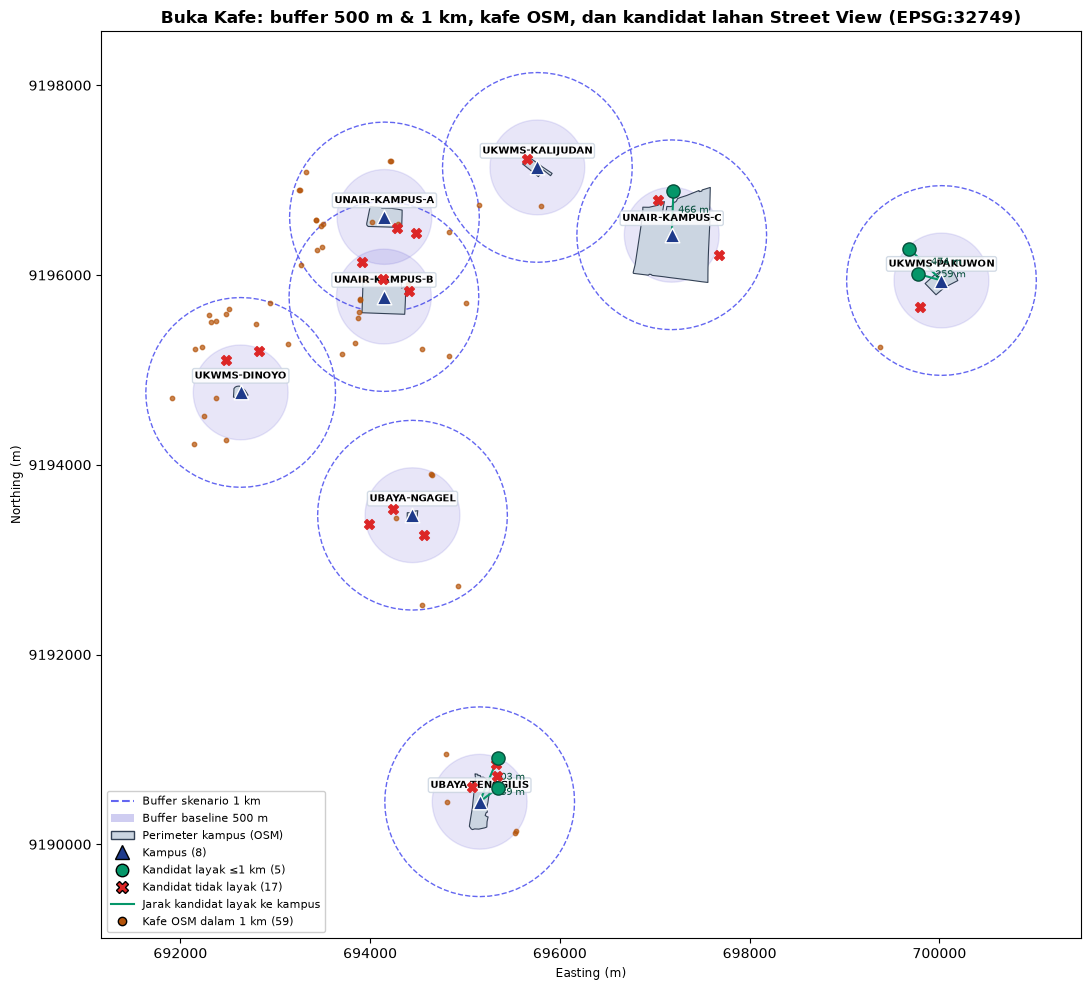

In [16]:
def plot_peta(kampus_titik, kampus_area, zona_500, zona_1000, kafe, kandidat, garis, title, filename=None):
    fig, ax = plt.subplots(figsize=(12, 10))
    zona_1000.plot(ax=ax, facecolor="none", edgecolor="#6366F1", linestyle="--", linewidth=1)
    zona_500.plot(ax=ax, facecolor="#4338CA", alpha=0.12, edgecolor="#4338CA", linewidth=1)
    kampus_area.plot(ax=ax, facecolor="#CBD5E1", edgecolor="#334155", linewidth=0.8)
    kafe.plot(ax=ax, color="#B45309", markersize=10, alpha=0.7, zorder=3)
    garis.plot(ax=ax, color="#059669", linewidth=1.5, zorder=3)
    kandidat.loc[~kandidat["layak_1000m"]].plot(ax=ax, color="#DC2626", marker="X", markersize=50, zorder=4)
    kandidat.loc[kandidat["layak_1000m"]].plot(ax=ax, color="#059669", edgecolor="#064E3B", markersize=90, zorder=5)
    kampus_titik.plot(ax=ax, color="#1E3A8A", marker="^", markersize=110, edgecolor="white", zorder=6)

    for row in kampus_titik.itertuples():
        ax.annotate(row.id, (row.geometry.x, row.geometry.y), xytext=(0, 10), textcoords="offset points",
                    ha="center", fontsize=7.5, fontweight="bold",
                    bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.85, edgecolor="#CBD5E1"))
    for row in garis.itertuples():
        tengah = row.geometry.interpolate(0.5, normalized=True)
        ax.annotate(f"{row.jarak_m:.0f} m", (tengah.x, tengah.y), xytext=(4, 0),
                    textcoords="offset points", fontsize=7, color="#064E3B")

    n_layak = int(kandidat["layak_1000m"].sum())
    legend_items = [
        Line2D([0], [0], color="#6366F1", linestyle="--", label="Buffer skenario 1 km"),
        Patch(facecolor="#4338CA", alpha=0.25, label="Buffer baseline 500 m"),
        Patch(facecolor="#CBD5E1", edgecolor="#334155", label="Perimeter kampus (OSM)"),
        Line2D([0], [0], marker="^", color="none", markerfacecolor="#1E3A8A", markersize=10, label=f"Kampus ({len(kampus_titik)})"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor="#059669", markersize=9, label=f"Kandidat layak ≤1 km ({n_layak})"),
        Line2D([0], [0], marker="X", color="none", markerfacecolor="#DC2626", markersize=9, label=f"Kandidat tidak layak ({len(kandidat) - n_layak})"),
        Line2D([0], [0], color="#059669", label="Jarak kandidat layak ke kampus"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor="#B45309", markersize=6, label=f"Kafe OSM dalam 1 km ({len(kafe)})"),
    ]
    ax.legend(handles=legend_items, loc="lower left", fontsize=8, framealpha=0.95)
    ax.set_aspect("equal")
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")
    ax.set_title(title, fontweight="bold")
    ax.ticklabel_format(style="plain", useOffset=False)
    fig.tight_layout()
    if filename:
        fig.savefig(filename, dpi=150)
    plt.show()

plot_peta(
    kampus_m, kampus_poly_m, buffers_500, buffers_1000, kafe_terpotong, lahan_j, garis,
    "Buka Kafe: buffer 500 m & 1 km, kafe OSM, dan kandidat lahan Street View (EPSG:32749)",
    filename=ROOT / "notebooks" / "peta_geopandas.png",
)

## 9. Transformasi 2D dengan matriks homogen

Transformasi (translasi, rotasi, skala, komposit) diterapkan ke poligon kampus Ubaya Tenggilis. Setiap transformasi ditulis sebagai matriks 3×3 homogen dan dikalikan ke setiap titik poligon. Hasilnya dicocokkan dengan `shapely.affinity` untuk membuktikan perhitungannya benar.

Skala terhadap titik tengah kampus = translasi ke origin → skala → translasi balik: **M = T(c) · S(s) · T(−c)**.

Matriks skala T(c) · S(1.5) · T(-c):
[[       1.5         0.    -347579.4 ]
 [       0.          1.5  -4595214.35]
 [       0.          0.          1.  ]]

Luas asli 8.79 ha -> setelah skala 1,5x: 19.78 ha (= 1,5² × asli)


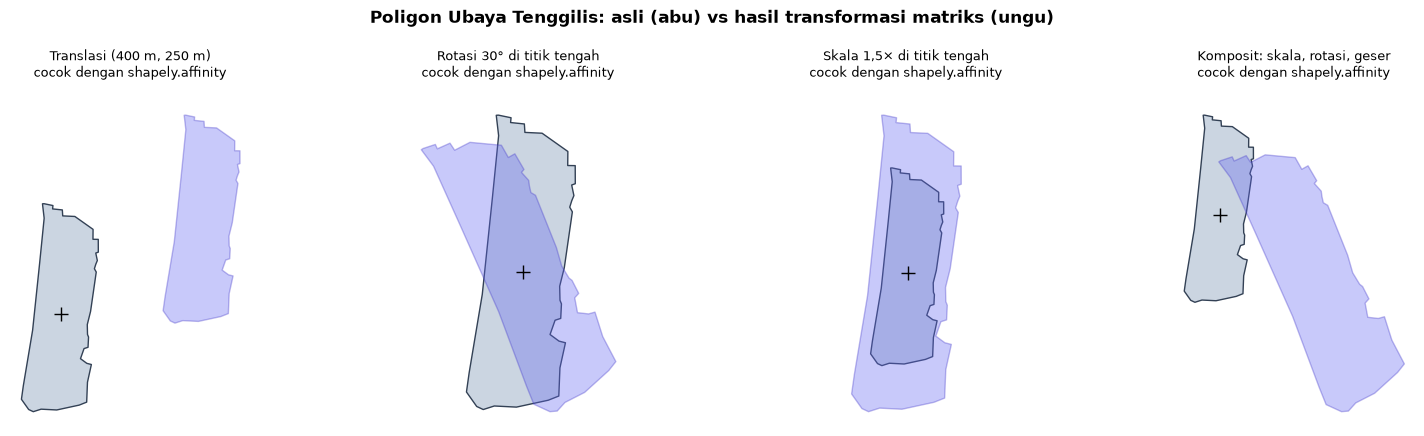

Transformation checks passed.


In [17]:
def T(tx, ty):
    return np.array([[1, 0, tx], [0, 1, ty], [0, 0, 1]], dtype=float)

def R(derajat):
    a = np.radians(derajat)
    return np.array([[np.cos(a), -np.sin(a), 0], [np.sin(a), np.cos(a), 0], [0, 0, 1]])

def S(sx, sy):
    return np.array([[sx, 0, 0], [0, sy, 0], [0, 0, 1]], dtype=float)

def terapkan(M, poligon):
    # Titik (x, y) -> (x, y, 1), kalikan M, ambil (x', y')
    xy1 = np.c_[np.asarray(poligon.exterior.coords), np.ones(len(poligon.exterior.coords))]
    return Polygon((M @ xy1.T).T[:, :2])

asli = tenggilis_poly
cx, cy = asli.centroid.x, asli.centroid.y

M_translasi = T(400, 250)
M_rotasi = T(cx, cy) @ R(30) @ T(-cx, -cy)
M_skala = T(cx, cy) @ S(1.5, 1.5) @ T(-cx, -cy)
M_komposit = T(300, -200) @ M_rotasi @ M_skala      # skala -> rotasi -> geser

transformasi = {
    "Translasi (400 m, 250 m)": (M_translasi, affinity.translate(asli, 400, 250)),
    "Rotasi 30° di titik tengah": (M_rotasi, affinity.rotate(asli, 30, origin=(cx, cy))),
    "Skala 1,5× di titik tengah": (M_skala, affinity.scale(asli, 1.5, 1.5, origin=(cx, cy))),
    "Komposit: skala, rotasi, geser": (
        M_komposit,
        affinity.translate(affinity.rotate(affinity.scale(asli, 1.5, 1.5, origin=(cx, cy)), 30, origin=(cx, cy)), 300, -200),
    ),
}

print("Matriks skala T(c) · S(1.5) · T(-c):")
print(M_skala)
print(f"\nLuas asli {asli.area / 1e4:.2f} ha -> setelah skala 1,5x: {terapkan(M_skala, asli).area / 1e4:.2f} ha (= 1,5² × asli)")

fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for ax, (judul, (M, hasil_shapely)) in zip(axes, transformasi.items()):
    hasil_manual = terapkan(M, asli)
    assert hasil_manual.equals_exact(hasil_shapely, tolerance=1e-6), judul
    gpd.GeoSeries([asli]).plot(ax=ax, facecolor="#CBD5E1", edgecolor="#334155")
    gpd.GeoSeries([hasil_manual]).plot(ax=ax, facecolor="#6366F1", alpha=0.35, edgecolor="#4338CA")
    ax.plot(cx, cy, "k+", markersize=10)
    ax.set_title(f"{judul}\ncocok dengan shapely.affinity", fontsize=9)
    ax.set_aspect("equal")
    ax.axis("off")
fig.suptitle("Poligon Ubaya Tenggilis: asli (abu) vs hasil transformasi matriks (ungu)", fontweight="bold")
fig.tight_layout()
plt.show()
print("Transformation checks passed.")

## 10. Animasi: buffer yang membesar dari 0 sampai 1 km

`FuncAnimation` memperlihatkan buffer Ubaya Tenggilis membesar setiap 50 m. Kafe OSM dan kandidat lahan yang masuk buffer berubah warna, dan penghitung di judul ikut bertambah. Garis putus-putus menandai batas baseline 500 m.

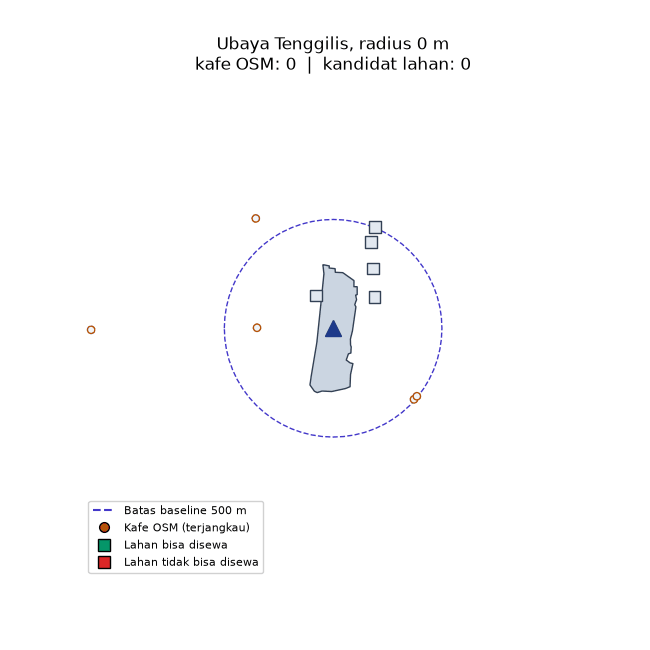

In [18]:
area_animasi = tenggilis_titik.buffer(skenario_m + 150)
kafe_area = kafe_m[kafe_m.intersects(area_animasi)]
lahan_area = lahan_j[lahan_j.intersects(area_animasi)]
jarak_kafe = kafe_area.distance(tenggilis_titik).to_numpy()
jarak_lahan = lahan_area.distance(tenggilis_titik).to_numpy()
radius_frames = list(range(0, skenario_m + 1, 50))

fig, ax = plt.subplots(figsize=(6.5, 6.5))
xmin, ymin, xmax, ymax = area_animasi.bounds
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.axis("off")
gpd.GeoSeries([tenggilis_buffer]).plot(ax=ax, facecolor="none", edgecolor="#4338CA", linestyle="--")
gpd.GeoSeries([tenggilis_poly]).plot(ax=ax, facecolor="#CBD5E1", edgecolor="#334155")
ax.plot(tenggilis_titik.x, tenggilis_titik.y, marker="^", color="#1E3A8A", markersize=12)
lingkaran = plt.Circle((tenggilis_titik.x, tenggilis_titik.y), 0, facecolor="#6366F1", alpha=0.18, edgecolor="#4338CA")
ax.add_patch(lingkaran)
titik_kafe = ax.scatter(kafe_area.geometry.x, kafe_area.geometry.y, s=28, c="#F1F5F9", edgecolors="#B45309", zorder=3)
titik_lahan = ax.scatter(lahan_area.geometry.x, lahan_area.geometry.y, s=70, marker="s", c="#E2E8F0", edgecolors="#334155", zorder=4)
ax.legend(handles=[
    Line2D([0], [0], color="#4338CA", linestyle="--", label="Batas baseline 500 m"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#B45309", markersize=7, label="Kafe OSM (terjangkau)"),
    Line2D([0], [0], marker="s", color="none", markerfacecolor="#059669", markersize=8, label="Lahan bisa disewa"),
    Line2D([0], [0], marker="s", color="none", markerfacecolor="#DC2626", markersize=8, label="Lahan tidak bisa disewa"),
], loc="lower left", fontsize=8, framealpha=0.9)
judul = ax.set_title("")

def gambar_frame(i):
    r = radius_frames[i]
    lingkaran.set_radius(r)
    titik_kafe.set_facecolor(np.where(jarak_kafe <= r, "#B45309", "#F1F5F9"))
    titik_lahan.set_facecolor(np.where(jarak_lahan <= r, np.where(lahan_area["bisa_disewa"], "#059669", "#DC2626"), "#E2E8F0"))
    judul.set_text(f"Ubaya Tenggilis, radius {r} m\nkafe OSM: {(jarak_kafe <= r).sum()}  |  kandidat lahan: {(jarak_lahan <= r).sum()}")
    return lingkaran, titik_kafe, titik_lahan, judul

animasi = FuncAnimation(fig, gambar_frame, frames=len(radius_frames), interval=250)
path_gif = ROOT / "notebooks" / "animasi_buffer.gif"
animasi.save(path_gif, writer=PillowWriter(fps=4))
plt.close(fig)
display(Image(filename=str(path_gif)))

## 11. Ekspor hasil

In [19]:
per_kampus.to_csv(PROC / "geopandas_hasil_per_kampus.csv", index=False)
peringkat.round(2).to_csv(PROC / "geopandas_peringkat_kandidat.csv", index=False)
print("Tersimpan:")
for f in ["data/processed/geopandas_hasil_per_kampus.csv", "data/processed/geopandas_peringkat_kandidat.csv",
          "notebooks/peta_geopandas.png", "notebooks/animasi_buffer.gif"]:
    assert (ROOT / f).exists()
    print(" -", f)

Tersimpan:
 - data/processed/geopandas_hasil_per_kampus.csv
 - data/processed/geopandas_peringkat_kandidat.csv
 - notebooks/peta_geopandas.png
 - notebooks/animasi_buffer.gif


## 12. Keterbatasan

1. **Data lahan dari Google Street View.** 22 titik diobservasi lewat panorama Street View pada 1–2 November 2026, bukan survei fisik di lapangan. Tanggal citra 2024–2026, jadi kondisi sekarang bisa berbeda. Semua titik perlu ditinjau tim.
2. **Data sewa dan luas belum ada** untuk titik observasi. Komponen itu tidak ditebak, sehingga cakupan skor di bawah 60%.
3. **Gerbang kampus dan indikator mahasiswa belum teramati**; tipe jalan hanya diisi bila terlihat jelas di Street View.
4. **Jarak berupa garis lurus** dari titik kampus, bukan jarak tempuh lewat jalan.
5. **Kafe OSM bisa tidak lengkap**: kafe baru atau yang tutup mungkin belum tercatat di OpenStreetMap.
6. **Buffer kampus bisa bertumpuk** (misalnya Unair A dan B), sehingga satu kafe bisa terhitung di dua kampus pada tabel per kampus; total kafe unik dihitung terpisah.